# BD
---

## ¿Qué son?

|| Ejemplos |
| -- | -- |
| Colección organizada de datos sobre un tema o contexto que se almacenan de forma persistente en un sistema informático para su posterior recuperación, análisis y/o transmisión | lista de estudiantes de un curso y sus notas |
| Los datos se **almacenan** usando un motor de bases de datos o SGBD (software que permite organizar y consultar los datos) | crear tablas para guardar los nombres de los estudiantes y sus notas |
| Los datos se **consultan** cuando se necesitan | lista de los mejores estudiantes |


## Tipos de modelos de BD (lógico)

* BD Relacionales (MR)
* BD Orientadas a Objetos (MOO)
* BD Documentales (MD)
* BD Jerárquicas / BD de Red
* BD Transaccionales / BD Multidimensionales

## Tipos de motores de BD

| Tipos | | Ejemplos |
| -- | -- | -- |
| **Relacionales (SQL)** | organizan los datos en tablas de manera relacional y evitan que los datos se repitan. Datos consistentes sin errores (ej. datos financieros) | **MySQL**, PostgreSQL, Microsoft SQL Server, **Oracle**, **SQLite**, MariaDB, Informix, Sybase, DB2, etc. |
| **No Relacionales (NoSQL)** | no usan tablas, usan documentos JSON no relacionados y los datos pueden repetirse en diferentes lugares para acceder más rápido. Para aplicaciones con grandes datos (ej. Redes Sociales) | Casandra, **mongoDB**, redis, neo4j, JanusGraph, ArangoDB, Google Cloud Firestore, Azure Cosmos DB, Amazon DynamoDB |

[Ranking de motores de BD](https://db-engines.com/en/ranking)

## Como diseñar una BD Relacional

1. Levantar requerimientos
1. Diseño conceptual: DER (entidades y relaciones). Cardinalidades: 1:1, 1:N, N:N

```mermaid
erDiagram
    Personas }|--|| Ciudades : ""
    Personas {
        INTEGER  id PK
        NVARCHAR nom
        INTEGER codCiu FK
    }
    Ciudades {
        INTEGER  codCiu PK
        NVARCHAR nomCiu
    }
```

1. Diseño lógico: tabular el DER (filas/registros y columnas/atributos) y normalizar la BD. Incorporar y clasificar claves en:
    * **PK (primarias)**: campo/s que identifican de forma única a cada fila de una tabla
    * **FK (foráneas)**: campo/s que contiene valores que coinciden con la clave primaria de otra tabla, necesarias para crear relaciones/vinculos entre tablas

**Personas**

| id | nom     | codCiu |
| -- | --      | --     |
| 1  | pablo   | 2      |
| 2  | ana     | 2      |
| 3  | carlos  | 1      |

**Ciudades**

| codCiu | nomCiu        |
| --     | --            |
| 1      | Mar del Plata |
| 2      | Mendoza       |
| 3      | Bariloche     |
| 4      | Puerto Iguazú |

2. Diseño físico: tipos de datos, dominios, indices, SQL

## Normalización BD Relacional

* Es el acto de organizar los datos, utilizando una serie de reglas evitando la redundancia de los datos y almacenando con el menor espacio posible.

| Legajo | Nombre | Materia | CodM | Carrera |
| --     | --     | --      | --   | --      |
| 1      | David  | LFORM   | 123  | INF     |
| 1      | David  | COMPIL  | 234  | INF     |
| 2      | Diego  | LFORM   | 123  | WEB     |
| 1      | David  | TCOMP   | 456  | INF     |

1. 1FN: Sin campos repetidos
1. 2FN: Cumple 1FN y cada campo debe tener una clave única
1. 3FN: Cumple 2FN y los campos que no son claves, no deben incluir dependencias transitiva (los campos no clave son dependientes de otros campos que tampoco son claves)

**ALUMNOS**

| Legajo | Nombre | idCarrera |
| --     | --     | --        |
| 1      | David  | 12345     |
| 2      | Diego  | 56789     |

**CARRERAS**

| IdCarrera | Carrera |
| --        | --      |
| 12345     | INF     |
| 56789     | WEB     |

**MATERIAS**

| CodM | Materia |
| --   | --      |
| 123  | LFORM   |
| 456  | TCOMP   |
| 234  | COMPIL  |

**CURSADAS**

| Legajo | CodM |
| --     | --   |
| 1      | 123  |
| 1      | 234  |
| 2      | 123  |
| 1      | 456  |

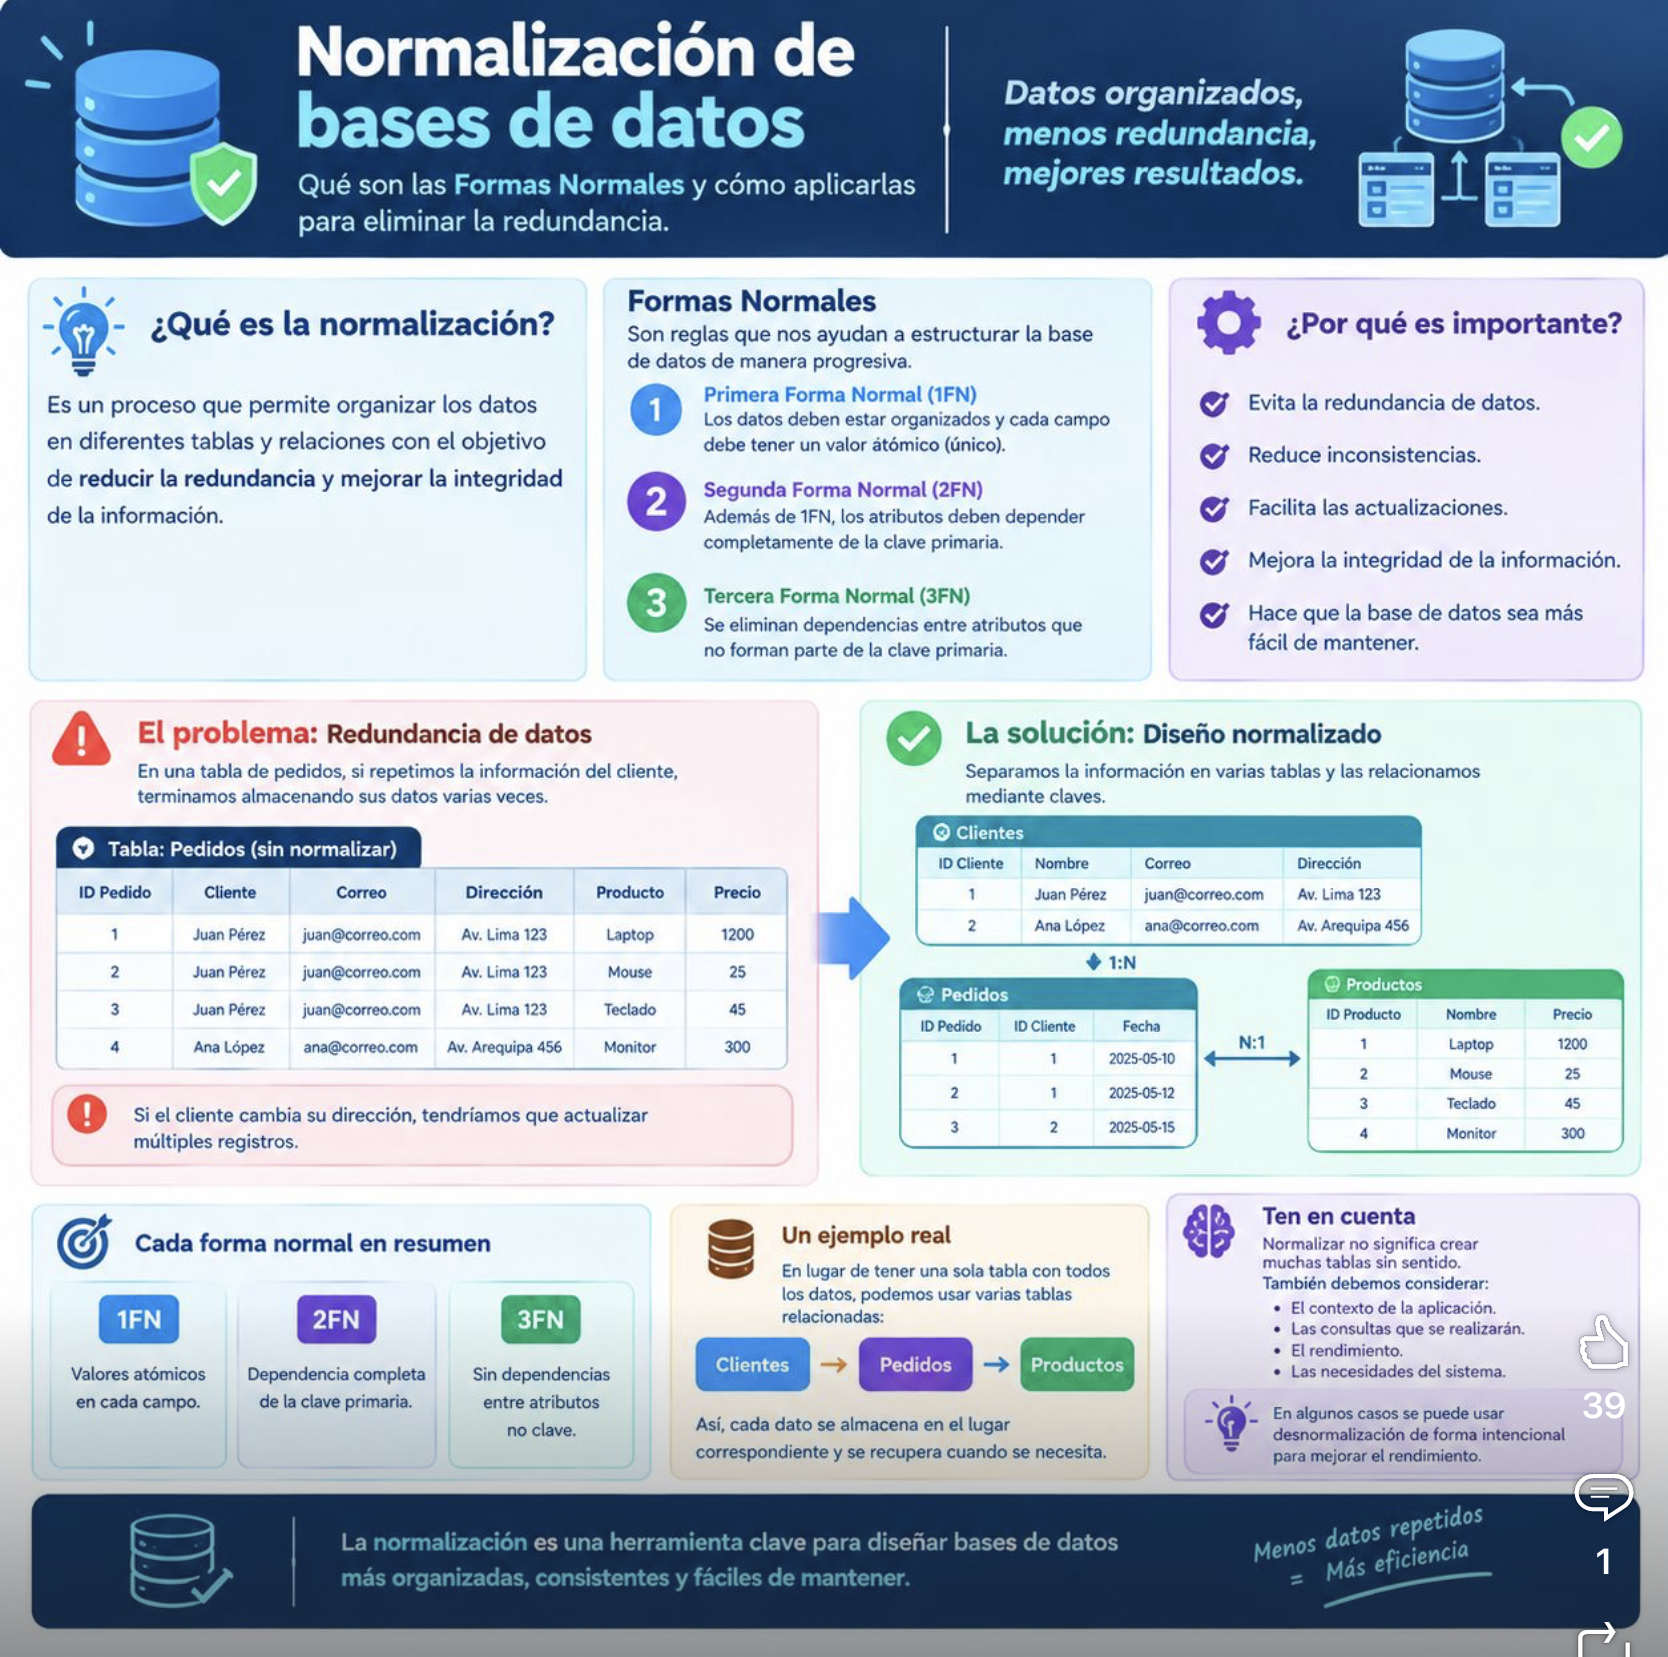

## SQL (Structured Query Language)

* Es un lenguaje estándar e interactivo de acceso a BD relacionales que permite especificar diversos tipos de operaciones en ellas (administrar y recuperar datos)
* Las consultas son códigos, utilizando sintaxis y palabras reservadas
  * Consultar datos de la BD, aunque la misma provenga de varias tablas => SELECT ... FROM ... [ WHERE ... GROUP BY ... HAVING ... ORDER BY ... ]

```sql
-- indica las columnas que se quieren consultar
SELECT nombre, autor, genero
-- selecciona las tablas
FROM libros
-- define las condiciones para que se cumpla la consulta
WHERE genero = 'Novela negra';
```

```sql
SELECT autor, COUNT(libroID)
FROM libros
WHERE genero = 'Novela negra'
-- muestra como se agruparán los registros. Se usan cuando existen funciones como COUNT()
GROUP BY autor
-- indica que condición debe cumplirse como resultado
HAVING COUNT(libroID) > 3
-- muesta el orden de la consulta
ORDER BY nombre ASC;

-- Orden de ejecución:
-- 1. FROM & JOIN
-- 2. WHERE
-- 3. GROUP BY
-- 4. HAVING
-- 5. SELECT
-- 6. ORDER BY
```

* Crear, modificar y borrar objetos de la BD => CREATE, ALTER, DROP
* Insertar, modificar y eliminar datos => INSERT, UPDATE, DELETE
* Controlar el acceso a la información => GRANT, REVOKE
* Controlar las transacciones => COMMIT, ROLLBACK

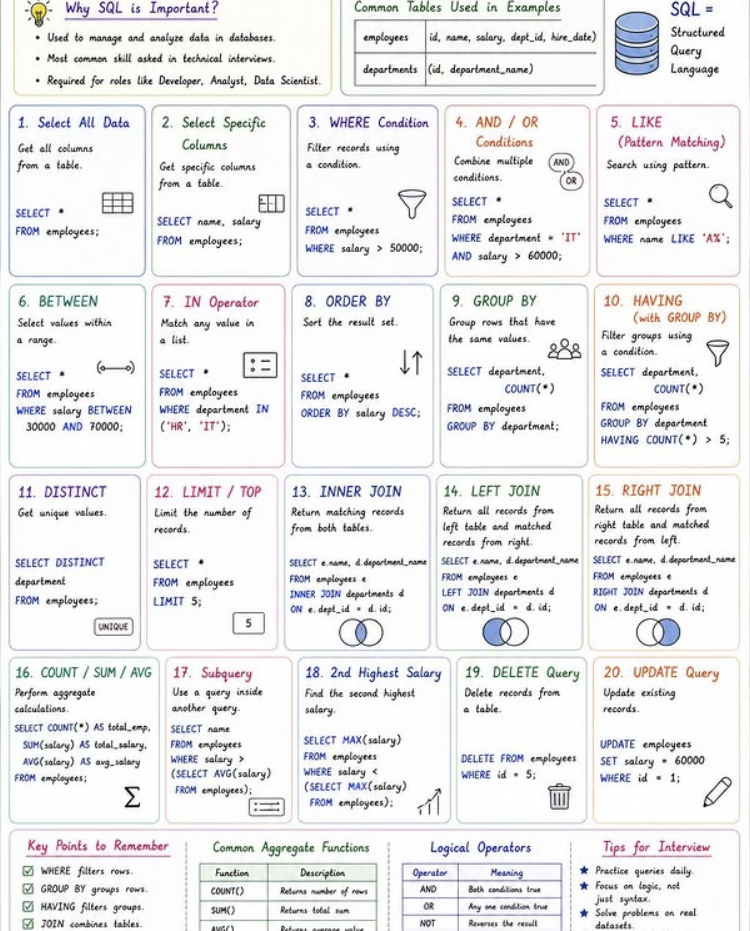

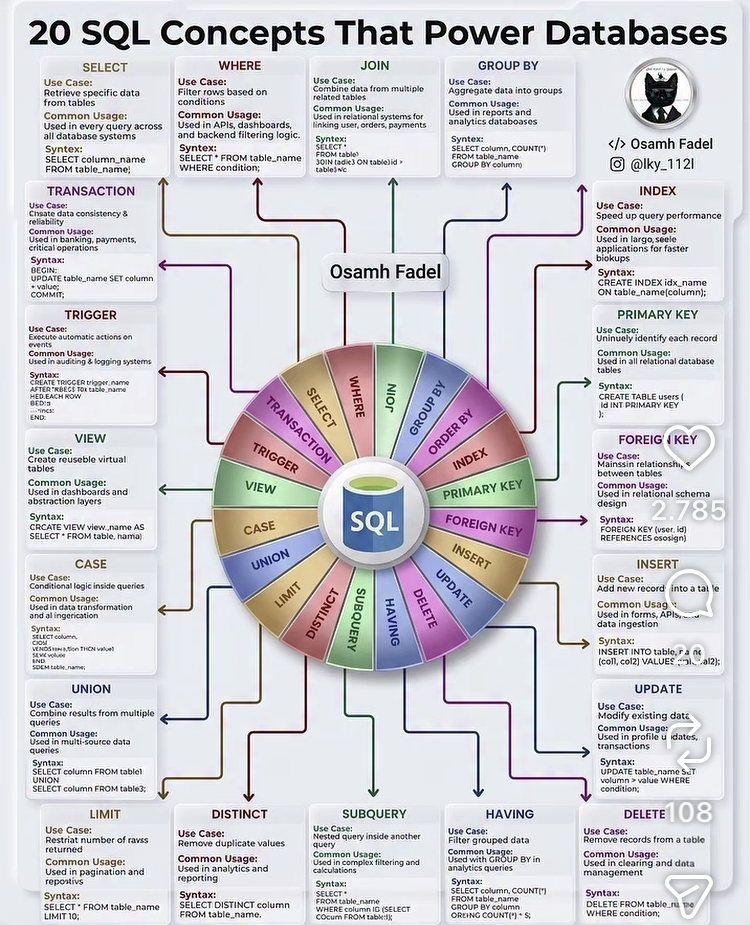